# C-Elegans Comparison

In [1]:
import sys
sys.path.append('..')
from utils.plotting import plot_n_hic, genomic_labels

from func_iou import *
from func_pileup import *

import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import bioframe as bf
from matplotlib_venn import venn2

In [2]:
# Analysis parameters
output_name = "v2.0.3"
save_path = f"/nfs/turbo/umms-minjilab/sionkim/miajet_revision/analysis_{output_name}"

# Pileup parameters
data_type = "oe"
expected_stack_size = 100

# Overlap parameters
iou_threshold = 0  # ANY overlap

exp_name_1 = "c-elegans-CA1200-L2-L3-JK07-JK08_control-auxin-1hr_hic_Kim-2023_GSE188849_ce10"
exp_name_2 = "c-elegans-JK05-L3_SMC3-auxin-1hr_hic_Kim-2023_GSE237663_ce10"
exp_name_3 = "c-elegans-JK06-L3_WAPL-auxin-1hr_hic_Kim-2023_GSE237663_ce10"

hic_file_1 = "/nfs/turbo/umms-minjilab/downloaded_data/c-elegans-CA1200-L2-L3-JK07-JK08_control-auxin-1hr_hic_Kim-2023_GSE188849_ce10.hic"
hic_file_2 = "/nfs/turbo/umms-minjilab/downloaded_data/c-elegans-JK05-L3_SMC3-auxin-1hr_hic_Kim-2023_GSE237663_ce10.hic"
hic_file_3 = "/nfs/turbo/umms-minjilab/downloaded_data/c-elegans-JK06-L3_WAPL-auxin-1hr_hic_Kim-2023_GSE237663_ce10.hic"

data_name = "C elegans control vs. depletion"

resolution = 5000
normalization = "VC_SQRT"

# Overlap parameter is relative to resolution
buffer_radius = 3 * resolution

# MIA-JET
result_type = "q_val_0.5-0.95"
f_pred_miajet_1_summary = f"/nfs/turbo/umms-minjilab/sionkim/miajet_revision/miajet/output_{output_name}/{exp_name_1}_chr_combined_{genomic_labels(resolution)}/{exp_name_1}_chr_combined_{result_type}_{genomic_labels(resolution)}_summary_table.csv"
f_pred_miajet_1_expanded = f"/nfs/turbo/umms-minjilab/sionkim/miajet_revision/miajet/output_{output_name}/{exp_name_1}_chr_combined_{genomic_labels(resolution)}/{exp_name_1}_chr_combined_{result_type}_{genomic_labels(resolution)}_expanded_table.csv"

f_pred_miajet_2_summary = f"/nfs/turbo/umms-minjilab/sionkim/miajet_revision/miajet/output_{output_name}/{exp_name_2}_chr_combined_{genomic_labels(resolution)}/{exp_name_2}_chr_combined_{result_type}_{genomic_labels(resolution)}_summary_table.csv"
f_pred_miajet_2_expanded = f"/nfs/turbo/umms-minjilab/sionkim/miajet_revision/miajet/output_{output_name}/{exp_name_2}_chr_combined_{genomic_labels(resolution)}/{exp_name_2}_chr_combined_{result_type}_{genomic_labels(resolution)}_expanded_table.csv"

f_pred_miajet_3_summary = f"/nfs/turbo/umms-minjilab/sionkim/miajet_revision/miajet/output_{output_name}/{exp_name_3}_chr_combined_{genomic_labels(resolution)}/{exp_name_3}_chr_combined_{result_type}_{genomic_labels(resolution)}_summary_table.csv"
f_pred_miajet_3_expanded = f"/nfs/turbo/umms-minjilab/sionkim/miajet_revision/miajet/output_{output_name}/{exp_name_3}_chr_combined_{genomic_labels(resolution)}/{exp_name_3}_chr_combined_{result_type}_{genomic_labels(resolution)}_expanded_table.csv"

names = [
    "Control",
    "SMC3 auxin 1 hr",
    "WAPL auxin 1 hr",
]

genomes = [
    "ce10",
    "ce10",
    "ce10",
]

miajet_table_list = [
    f_pred_miajet_1_summary,
    f_pred_miajet_2_summary,
    f_pred_miajet_3_summary,
]

miajet_position_list = [
    f_pred_miajet_1_expanded,
    f_pred_miajet_2_expanded,
    f_pred_miajet_3_expanded,
]

In [3]:
# Load MIA-Jet results
data_name += f" (MIA-Jet {result_type})"

tables = []
positions = []
for f_miajet_table, f_miajet_position in zip(miajet_table_list, miajet_position_list):
    tables.append(pd.read_csv(f_miajet_table, comment="#"))
    positions.append(pd.read_csv(f_miajet_position, comment="#"))

In [4]:
# Establish the common chromosomes between the 0hr and 6hr
common_chroms = []
for t in tables:
    common_chroms += t["chrom"].unique().tolist()

common_chroms = set(list(common_chroms))
common_chroms

{'chrI', 'chrII', 'chrIII', 'chrIV', 'chrV', 'chrX'}

In [5]:
hic_file = [hic_file_1, hic_file_2, hic_file_3]

position_dict = dict(zip(names, positions))
table_dict = dict(zip(names, tables))

chrom_sizes = bf.fetch_chromsizes(genomes[0], as_bed=True)

## Agg: reference

### Fixed length

In [6]:
fixed_window_size = 350e3

In [7]:
# Regenerate the start and end positions for the aggregation
# Reference locations are the jets called in names[0] (Control)
common_bed_df = generate_bed_3(tables[0], positions[0], project_midpoint_to_diag=True, eps=fixed_window_size // 2)

In [8]:
agg_map = []
vmaxes = []
vmins = []
df_stack = []

for idx in range(len(names)):
    # Get pileups at the reference locations for each Hi-C map
    s, d = get_pileups(
        hic_file=hic_file[idx],
        bed_df_in=common_bed_df,
        resolution=resolution,
        chrom_sizes=chrom_sizes,
        chromosomes='all',
        window_range=(None, None),
        data_type=data_type,
        normalization=normalization,
        sort=False,
    )

    # Remove centromeres and resize square stacks
    s, d = remove_stacks(s, d, resolution=resolution, fixed_window_size=fixed_window_size)

    if data_type == "observed":
        s = np.log10(s + 1) # log transform for visualization

    a = np.nanmean(s, axis=0)
    vmaxes.append(np.nanpercentile(a, 99))  # store the 99th percentile for color scaling
    vmins.append(np.nanpercentile(a, 1))  # store the 1st percentile for color scaling
    agg_map.append(a)  # average over all stacks
    df_stack.append(d)  # store the DataFrame for later use

  0%|          | 0/109 [00:00<?, ?it/s]

  3%|▎         | 3/109 [00:00<00:03, 29.50it/s]

  7%|▋         | 8/109 [00:00<00:02, 38.06it/s]

 11%|█         | 12/109 [00:00<00:03, 32.24it/s]

 15%|█▍        | 16/109 [00:00<00:02, 32.61it/s]

 18%|█▊        | 20/109 [00:00<00:02, 33.69it/s]

... (84 outputs left out)

 93%|█████████▎| 101/109 [00:04<00:00, 29.62it/s]

 96%|█████████▋| 105/109 [00:04<00:00, 31.68it/s]

100%|██████████| 109/109 [00:04<00:00, 21.80it/s]

100%|██████████| 109/109 [00:04<00:00, 22.84it/s]

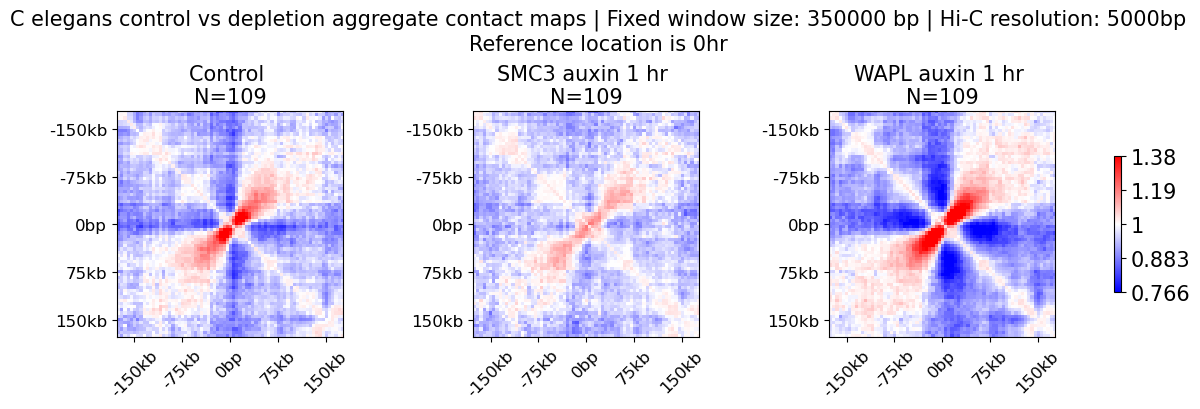

In [9]:
titles = [f"{names[i]} \nN={len(df_stack[i])}" for i in range(len(names))]

plot_n_hic(
    agg_map,
    suptitle=f"C elegans control vs depletion aggregate contact maps | Fixed window size: {int(fixed_window_size)} bp | Hi-C resolution: {resolution}bp\nReference location is 0hr",
    resolution=resolution,
    cmap_label=None,
    titles=titles,
    cmap='bwr',
    vcenter=1,
    standardize_cbar=True,
    show=True, 
    vmax=vmaxes,
    vmin=vmins,
    share_xy=False,
    ppr=4,
    figsize=(4 * 3, 4),
    savepath=f"{save_path}/{data_name}_reference0hr_agg_map-{data_type}_fixed_ws-{fixed_window_size}.png",
    cbar_fontsize=15,
    fig_fontsize=15,
    tick_fontsize=12,
    center_window=True,
    hide_axis=False,
)

## Agg all called

### Fixed length

In [10]:
# Regenerate the start and end positions for the aggregation
bed_tables = []
for s, e in zip(tables, positions):
    bed_tables.append(generate_bed_3(s, e, project_midpoint_to_diag=True, eps=fixed_window_size // 2))

In [11]:
agg_map = []
vmaxes = []
vmins = []
df_stack = []

for idx, bed_df in enumerate(bed_tables):
    # Get pileups for each bed_df
    s, d = get_pileups(
        hic_file=hic_file[idx],
        bed_df_in=bed_df,
        resolution=resolution,
        chrom_sizes=chrom_sizes,
        chromosomes='all',
        window_range=(None, None),
        data_type=data_type,
        normalization=normalization,
        sort=False,
    )

    # Remove centromeres and resize square stacks
    s, d = remove_stacks(s, d, resolution=resolution, fixed_window_size=fixed_window_size, verbose=True)

    if data_type == "observed":
        s = np.log10(s + 1) # log transform for visualization

    a = np.nanmean(s, axis=0)
    vmaxes.append(np.nanpercentile(a, 99))  # store the 99th percentile for color scaling
    vmins.append(np.nanpercentile(a, 1))   # store the 1st percentile for color scaling
    agg_map.append(a)  # average over all stacks
    df_stack.append(d)  # store the DataFrame for later use

  0%|          | 0/109 [00:00<?, ?it/s]

  5%|▍         | 5/109 [00:00<00:02, 41.95it/s]

  9%|▉         | 10/109 [00:00<00:02, 35.84it/s]

 13%|█▎        | 14/109 [00:00<00:02, 36.28it/s]

 17%|█▋        | 18/109 [00:00<00:02, 36.22it/s]

 20%|██        | 22/109 [00:00<00:02, 30.63it/s]

... (139 outputs left out)

 99%|█████████▊| 388/393 [00:12<00:00, 31.84it/s]

100%|█████████▉| 392/393 [00:12<00:00, 28.30it/s]

100%|██████████| 393/393 [00:12<00:00, 32.07it/s]

Expected array size: 71.0 (fixed_window_size=350000.0, resolution=5000)
Removing stack at index 180 with shape (70, 70). Region: chrI:-144697.588-205302.412
Removing stack at index 305 with shape (70, 70). Region: chrIII:-112444.99799999999-237555.002
Removing stack at index 381 with shape (70, 70). Region: chrII:-15862.944499999983-334137.0555


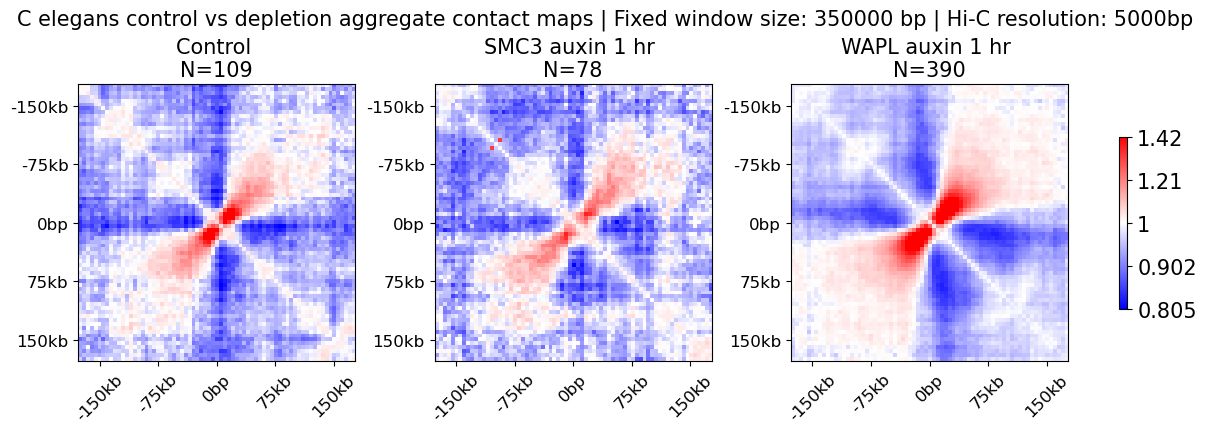

In [12]:
titles = [f"{names[i]} \nN={len(df_stack[i])}" for i in range(len(names))]

plot_n_hic(
    agg_map,
    suptitle=f"C elegans control vs depletion aggregate contact maps | Fixed window size: {int(fixed_window_size)} bp | Hi-C resolution: {resolution}bp",
    resolution=resolution,
    cmap_label=None,
    titles=titles,
    cmap='bwr',
    vcenter=1,
    standardize_cbar=True,
    show=True, 
    vmax=vmaxes,
    # vmin=vmins,
    share_xy=False,
    ppr=4,
    figsize=(4 * 3, 4.2),
    savepath=f"{save_path}/{data_name}_all_agg_map-{data_type}_fixed_ws-{fixed_window_size}.png",
    cbar_fontsize=15,
    fig_fontsize=15,
    tick_fontsize=12,
    hide_axis=False,
    center_window=True,
)

## Compute overlaps

In [13]:
# COMPUTE OVERLAPS
results = pd.DataFrame(index=names, columns=names, dtype=int).fillna(0)
unique_identifiers = []
name_pairs = []
# fill main diagonal with the total number of jets from each condition
for n in names:
    results.loc[n, n] = len(table_dict[n])

for n1, n2 in itertools.combinations(names, 2):

    print("-" * 20)
    print(f"Comparing {n1} and {n2}...")

    genome_wide_overlap = 0
    identifiers = []

    for chrom in common_chroms:

        # IOU method is per-chromosome so filter each table by chromosome
        t1 = position_dict[n1].loc[position_dict[n1]["chrom"] == chrom]
        t2 = position_dict[n2].loc[position_dict[n2]["chrom"] == chrom]

        if t1.empty or t2.empty:
            # if any of the two tables are empty then no need to check for overlaps.. there is none
            continue

        # Compute the pairs of jets in each direction
        pairs12 = match_by_iou(t1, t2, buffer_radius=buffer_radius, iou_threshold=iou_threshold, x_label="x (bp)", y_label="y (bp)")
        pairs21 = match_by_iou(t2, t1, buffer_radius=buffer_radius, iou_threshold=iou_threshold, x_label="x (bp)", y_label="y (bp)")

        # Construct graph and find unique pairs
        pairs = unique_pairs(pairs12, pairs21, method="optimal")

        genome_wide_overlap += len(pairs)
        identifiers += pairs # extend the list

    # Update results table
    results.loc[n1, n2] = genome_wide_overlap
    results.loc[n2, n1] = genome_wide_overlap  # symmetric

    unique_identifiers.append(identifiers)
    name_pairs.append((n1, n2))

print("Genome-wide overlaps:")
print(results)

--------------------
Comparing Control and SMC3 auxin 1 hr...
--------------------
Comparing Control and WAPL auxin 1 hr...


--------------------
Comparing SMC3 auxin 1 hr and WAPL auxin 1 hr...


Genome-wide overlaps:
                 Control  SMC3 auxin 1 hr  WAPL auxin 1 hr
Control            109.0             27.0             83.0
SMC3 auxin 1 hr     27.0             78.0             39.0
WAPL auxin 1 hr     83.0             39.0            393.0


In [14]:
def safe_int(x):
    try:
        return int(x)
    except ValueError:
        return x

In [15]:
# COLLECT AGG DATA
safe_convert = np.vectorize(safe_int)
agg_map_pairs = [] # aggregate contact map data
for (n1, n2), pairs in zip(name_pairs, unique_identifiers):

    if len(pairs) == 0:
        uid1 = np.array([])
        uid2 = np.array([])
    else:
        uid1 = safe_convert(np.array(pairs)[:, 0])  # unique identifiers from n1
        uid2 = safe_convert(np.array(pairs)[:, 1])  # unique identifiers from n2

    # Summary dataframes
    df_A = table_dict[n1]
    df_B = table_dict[n2]
    # Expanded dataframes
    df_pos_A = position_dict[n1]
    df_pos_B = position_dict[n2]

    # Split jets into "A only", "A & B" (taken from A), and "B only"
    df_intersection = df_A[df_A["unique_id"].isin(uid1)].reset_index(drop=True)
    df_diff_A = df_A[~df_A["unique_id"].isin(uid1)].reset_index(drop=True)
    df_diff_B = df_B[~df_B["unique_id"].isin(uid2)].reset_index(drop=True)

    df_pos_intersection = df_pos_A[df_pos_A["unique_id"].isin(uid1)].reset_index(drop=True)
    df_pos_diff_A = df_pos_A[~df_pos_A["unique_id"].isin(uid1)].reset_index(drop=True)
    df_pos_diff_B = df_pos_B[~df_pos_B["unique_id"].isin(uid2)].reset_index(drop=True)

    # Make bed files to get stacks
    bed_intersection = generate_bed_2(df_intersection, df_pos_intersection, eps=resolution * 5, fraction=1.5)
    bed_diff_A = generate_bed_2(df_diff_A, df_pos_diff_A, eps=resolution * 5, fraction=1.5)
    bed_diff_B = generate_bed_2(df_diff_B, df_pos_diff_B, eps=resolution * 5, fraction=1.5)

    A_idx = names.index(n1)
    B_idx = names.index(n2)

    bed_frames = [bed_diff_A, bed_intersection, bed_diff_B]
    chrom_sizes_comparison = [bf.fetch_chromsizes(genomes[A_idx]), bf.fetch_chromsizes(genomes[A_idx]), bf.fetch_chromsizes(genomes[B_idx])]
    hic_file_comparison = [hic_file[A_idx], hic_file[A_idx], hic_file[B_idx]]

    agg_map = []
    for j, bed_df in enumerate(bed_frames):
        # Get pileups for each bed_df
        s, d, r = get_pileups_dynamic_resolution(
            hic_file=hic_file_comparison[j],
            bed_df_in=bed_df,
            expected_stack_size=expected_stack_size,
            chrom_sizes=chrom_sizes_comparison[j],
            chromosomes='all',
            window_range=(None, None),
            data_type=data_type,
            normalization=normalization,
            sort=True,
            verbose=True
        )

        # Remove centromeres and resize square stacks
        s, d = remove_and_resize_square_stacks(s, d, expected_stack_size)

        if data_type == "observed":
            s = np.log10(s + 1) # log transform for visualization

        agg_map.append(np.mean(s, axis=0))  # average over all stacks

    agg_map_pairs.append(agg_map)

agg_map_pairs = np.array(agg_map_pairs)

Retrieving pileups:   0%|          | 0/82 [00:00<?, ?it/s]

Retrieving pileups:   4%|▎         | 3/82 [00:00<00:02, 29.59it/s]

Retrieving pileups:   9%|▊         | 7/82 [00:00<00:02, 32.04it/s]

Retrieving pileups:  13%|█▎        | 11/82 [00:00<00:02, 27.13it/s]

Retrieving pileups:  20%|█▉        | 16/82 [00:00<00:02, 31.90it/s]

Retrieving pileups:  24%|██▍       | 20/82 [00:00<00:01, 32.73it/s]

... (310 outputs left out)

Retrieving pileups:  98%|█████████▊| 346/354 [00:12<00:00, 26.55it/s]

Retrieving pileups:  99%|█████████▉| 350/354 [00:13<00:00, 28.88it/s]

Retrieving pileups: 100%|██████████| 354/354 [00:13<00:00, 30.49it/s]

Retrieving pileups: 100%|██████████| 354/354 [00:13<00:00, 26.79it/s]

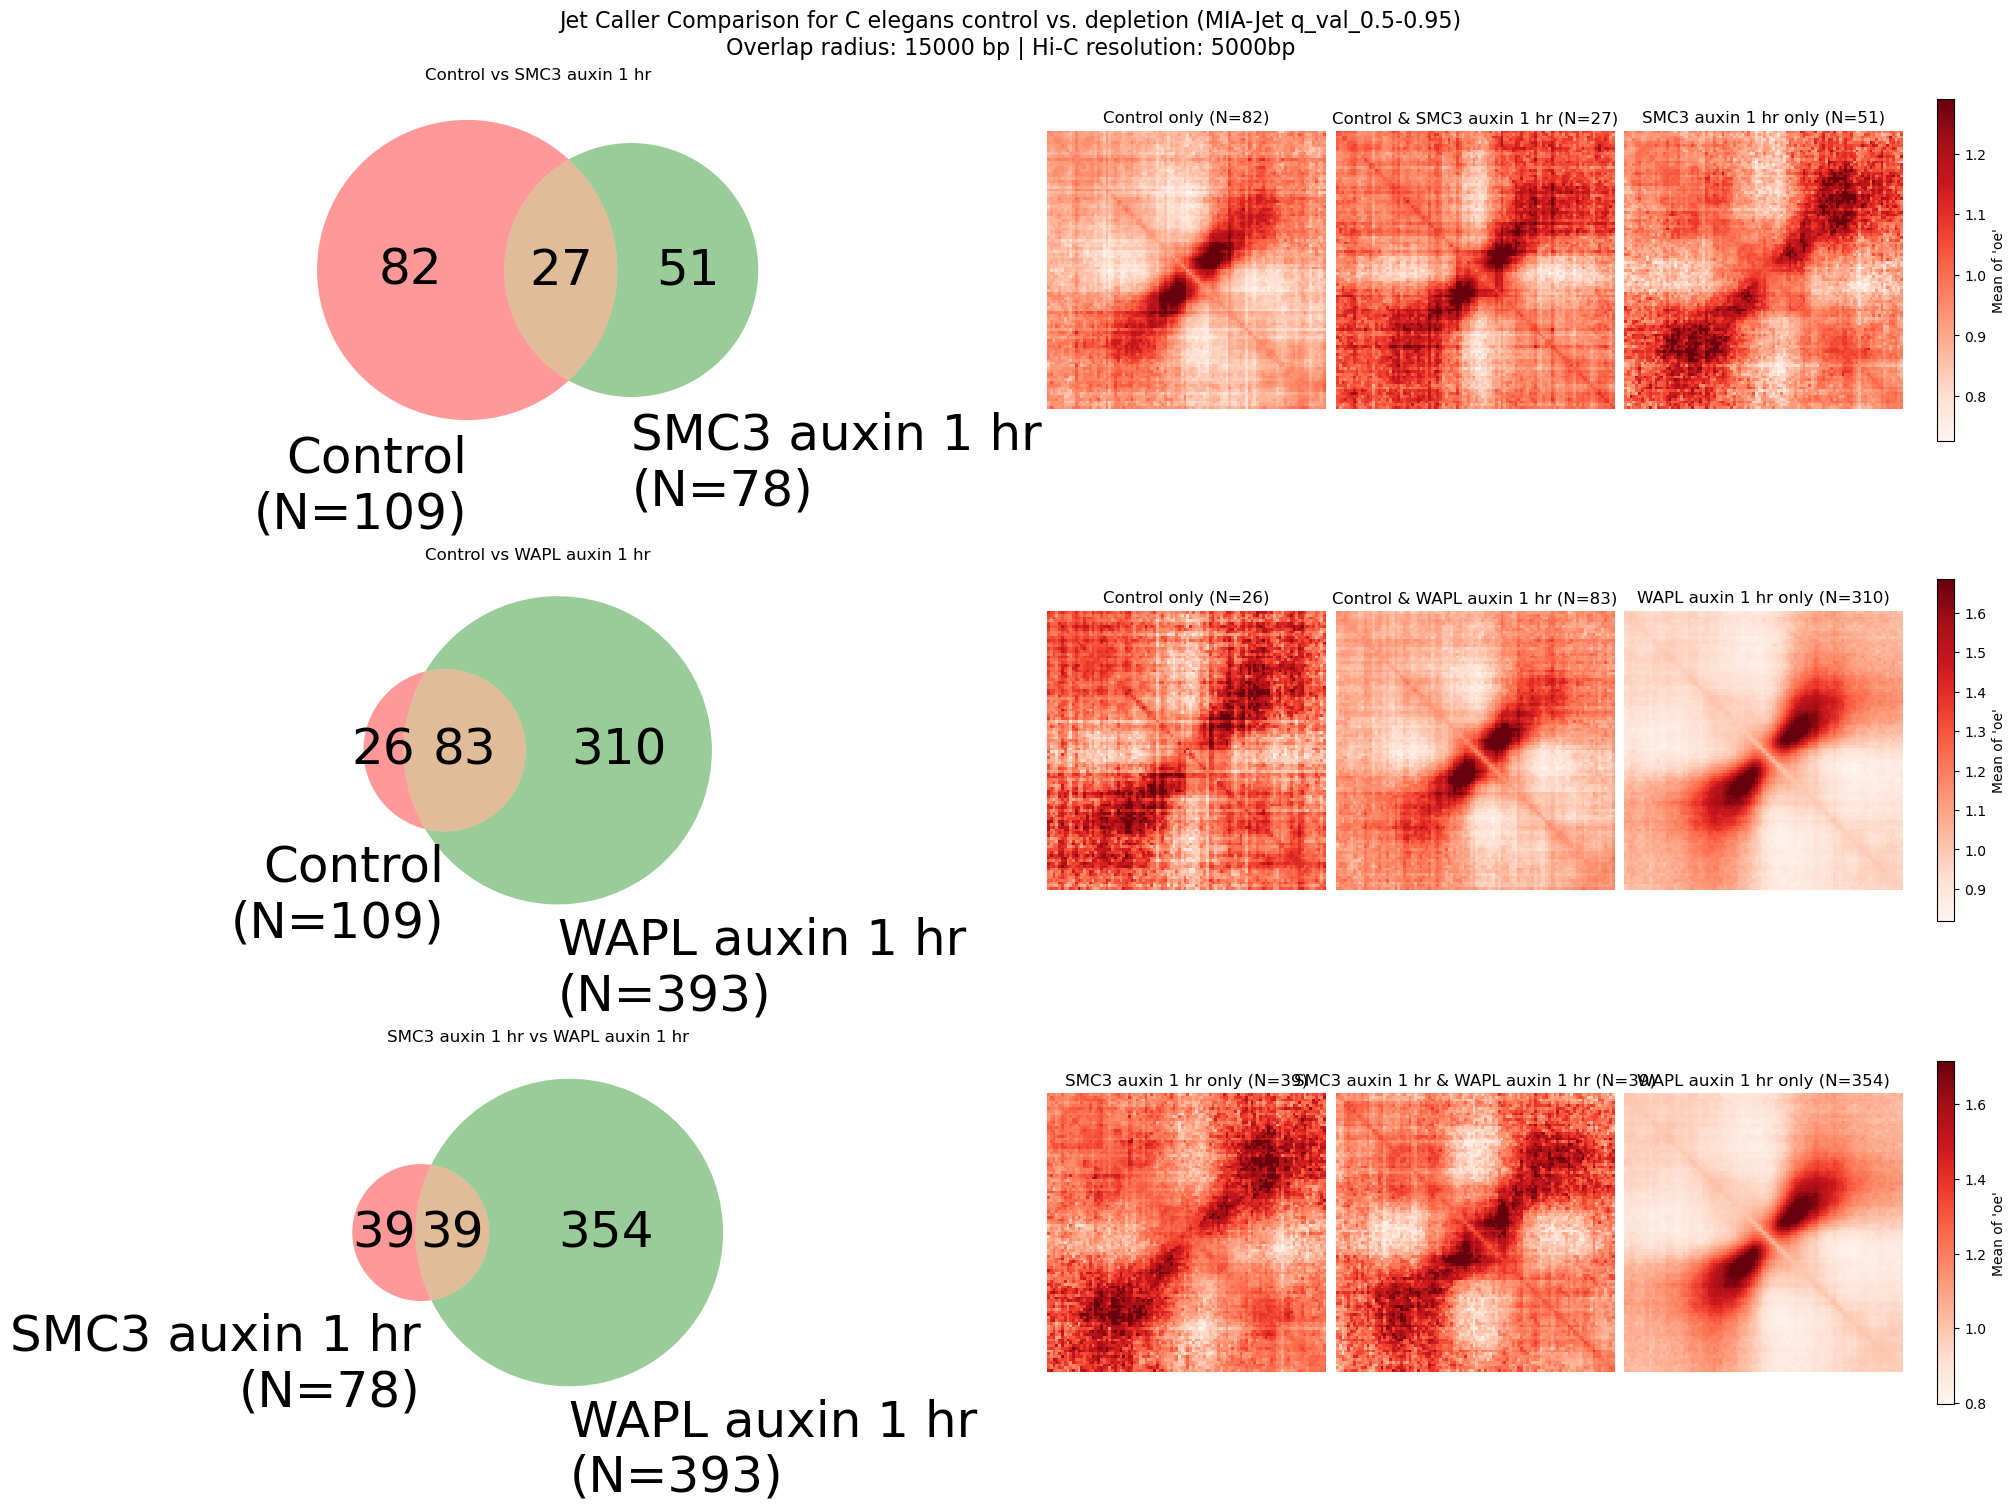

In [16]:
# every pairwise combination of table names
pairs = list(itertools.combinations(names, 2))
num_pairs = len(pairs)

fig, axes = plt.subplots(num_pairs, 4, figsize=(5*4, 5*num_pairs), layout='constrained', width_ratios=[2, 1, 1, 1])

for row, (A, B) in enumerate(pairs):
    # compute overlaps as before
    total_A = results.loc[A, A]
    total_B = results.loc[B, B]
    inter   = results.loc[A, B]
    only_A  = total_A - inter
    only_B  = total_B - inter

    # column 0: the Venn
    ax = axes[row, 0]
    v = venn2(subsets=(int(only_A), int(only_B), int(inter)),
            #   set_colors=(palette[A], palette[B]),
          set_labels=(f"{A}\n(N={int(total_A)})", f"{B}\n(N={int(total_B)})"),
          ax=ax)
    
    for txt in v.subset_labels:
        if txt is not None:
            txt.set_fontsize(36)
    for txt in v.set_labels:
        if txt is not None:
            txt.set_fontsize(36)

    ax.set_title(f"{A} vs {B}")

    # columns 1–3: the three imshows
    # agg_map_pairs.shape == (n_pairs, 3, H, W)
    titles = [f"{A} only", f"{A} & {B}", f"{B} only"]
    counts = [int(only_A), int(inter), int(only_B)]
    row_imgs = agg_map_pairs[row]
    row_vmax = max(np.percentile(img, 99) for img in row_imgs)
    for col_idx in range(3):
        ax = axes[row, col_idx+1]
        img = agg_map_pairs[row, col_idx]
        im = ax.imshow(img, cmap="Reds", interpolation="none", vmax=np.percentile(img, 99))
        ax.set_title(f"{titles[col_idx]} (N={counts[col_idx]})")
        ax.axis('off')
    fig.colorbar(im, ax=axes[row, 1:], fraction=0.02, pad=0.04, label=f"Mean of '{data_type}'")


fig.suptitle(f"Jet Caller Comparison for {data_name}\nOverlap radius: {int(buffer_radius)} bp | Hi-C resolution: {resolution}bp", fontsize=16)

# plt.savefig(f"{save_path}/{data_name}_{resolution}_{result_type}_venn_diagram-agg.png", dpi=300)

plt.show()